# Project 4: NLP & Sentiment Analysis on IMDB Dataset
**Internship Task: Decode Labs - Data Science**

### Objective:
Build a complete Machine Learning and Natural Language Processing (NLP) pipeline to read, mathematically represent, and categorize unstructured human movie reviews into **Positive** or **Negative** sentiment.

### Key Pipeline Components:
1. **Exploratory Data Analysis (EDA)**: Class balance, review text length, vocabulary exploration.
2. **Strict Text Preprocessing**: Tokenization, HTML tag stripping, special character removal, negation-aware stop-word filtering, and WordNet Lemmatization.
3. **Mathematical Representation (TF-IDF)**: Transforming text into numerical sparse matrices with unigram + bigram n-grams.
4. **Machine Learning Classifiers**:
   - Multinomial Naive Bayes (`MultinomialNB`)
   - Linear Support Vector Machine (`LinearSVC`)
   - Logistic Regression
5. **Model Evaluation & Visualization**: Confusion Matrix heatmaps, ROC-AUC curves, classification reports, and top predictive n-gram analysis.
6. **Interactive Sentiment Predictor**: Real-time sentiment classification tool for new, user-provided reviews.


## 1. Imports and Environment Setup


In [1]:
import os
import re
import string
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)
import joblib

# Set aesthetic styling for charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# Download required NLTK resources
for pkg in ['stopwords', 'wordnet', 'punkt', 'punkt_tab', 'omw-1.4']:
    nltk.download(pkg, quiet=True)

print("✓ Libraries loaded and NLTK resources ready!")


✓ Libraries loaded and NLTK resources ready!


## 2. Dataset Loading & Exploratory Data Analysis (EDA)


In [2]:
# Load the IMDB Dataset
DATA_PATH = "IMDB Dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns\n")
display(df.head(5))


Dataset Shape: 50,000 rows, 2 columns



,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Data integrity & null checks
print("=== Dataset Information ===")
df.info()

print("\nMissing values count:")
print(df.isnull().sum())


=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing values count:
review       0
sentiment    0
dtype: int64


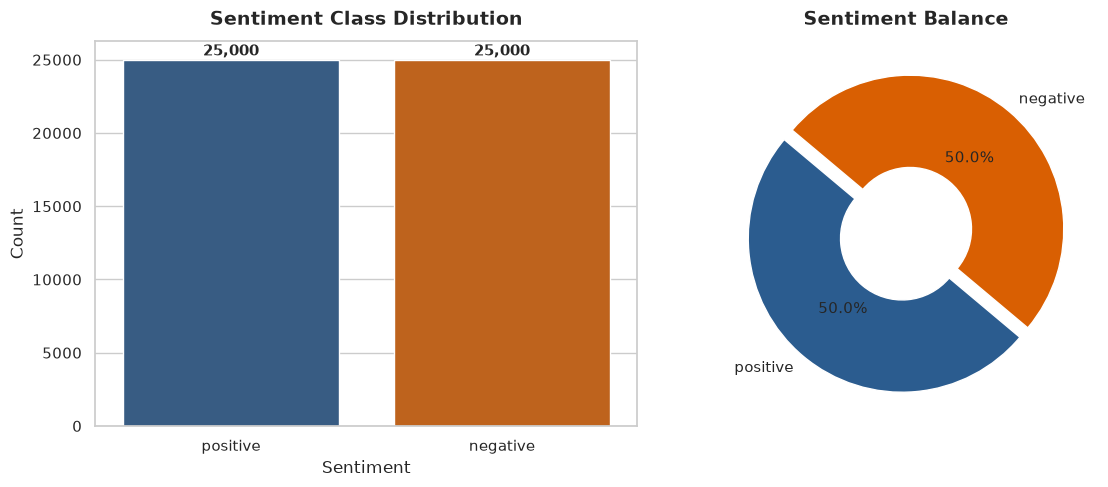

Target mapping: {'negative': 0, 'positive': 1}


In [4]:
# Target variable distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = df['sentiment'].value_counts()
colors = ['#2b5c8f', '#d95f02']

# Bar Chart
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=colors)
axes[0].set_title("Sentiment Class Distribution", fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel("Sentiment", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')

# Pie Chart
axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=colors,
            startangle=140, explode=(0.04, 0.04), wedgeprops=dict(width=0.6, edgecolor='w'))
axes[1].set_title("Sentiment Balance", fontsize=14, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

# Map sentiment labels to binary integers: positive = 1, negative = 0
df['target'] = df['sentiment'].map({'positive': 1, 'negative': 0})
print("Target mapping: {'negative': 0, 'positive': 1}")


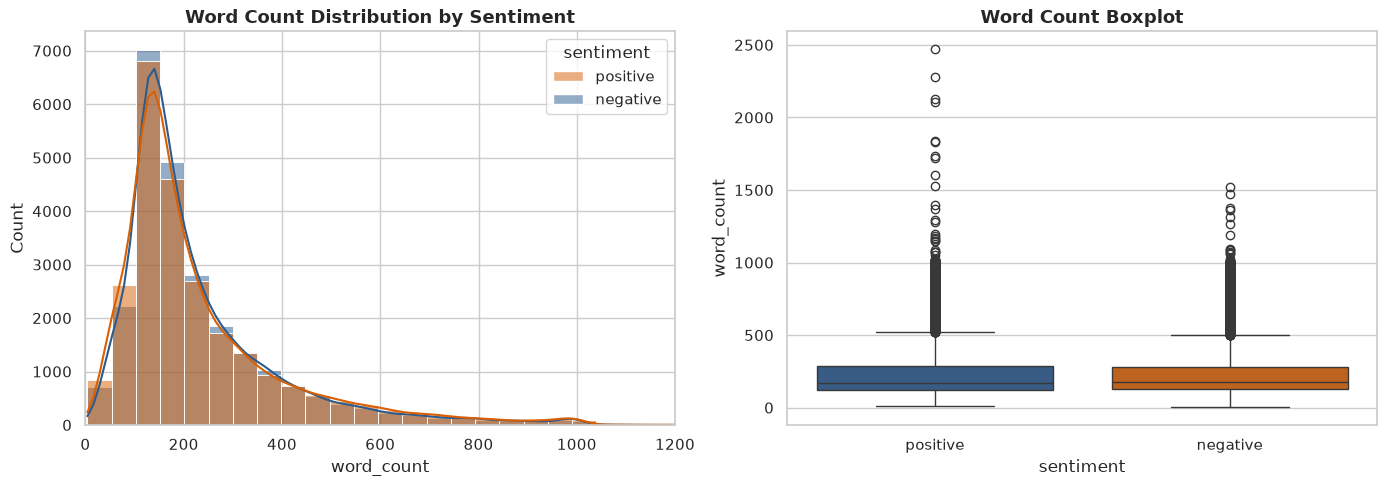

          word_count                                                    \
               count       mean         std   min    25%    50%    75%   
sentiment                                                                
negative     25000.0  229.46456  164.947795   4.0  128.0  174.0  278.0   
positive     25000.0  232.84932  177.497046  10.0  125.0  172.0  284.0   

                  char_count                                               \
              max      count        mean          std   min    25%    50%   
sentiment                                                                   
negative   1522.0    25000.0  1294.06436   945.892669  32.0  706.0  973.0   
positive   2470.0    25000.0  1324.79768  1031.492627  65.0  691.0  968.0   

                             
               75%      max  
sentiment                    
negative   1567.25   8969.0  
positive   1614.00  13704.0  


In [5]:
# Analyze Review Word and Character Lengths
df['char_count'] = df['review'].apply(len)
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='word_count', hue='sentiment', bins=50, kde=True, ax=axes[0], palette=['#d95f02', '#2b5c8f'])
axes[0].set_title("Word Count Distribution by Sentiment", fontsize=13, fontweight='bold')
axes[0].set_xlim(0, 1200)

sns.boxplot(data=df, x='sentiment', y='word_count', ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_title("Word Count Boxplot", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print(df.groupby('sentiment')[['word_count', 'char_count']].describe())


## 3. Strict Text Preprocessing Pipeline
In NLP, raw unstructured human text contains HTML tags (`<br />`), punctuation, capitalization inconsistencies, noise words (stopwords), and inflected forms.

Our pre-processing pipeline consists of:
1. **HTML & URL Stripping**: Removing web markup and links.
2. **Lowercasing**: Unifying casing across words.
3. **Special Character Removal**: Stripping punctuation and non-alphanumeric symbols.
4. **Negation-Aware Stop-Word Removal**: Keeping crucial sentiment modulators (`not`, `never`, `no`, `didn't`) while filtering standard fluff words (`the`, `is`, `at`, `which`).
5. **WordNet Lemmatization**: Reducing words to base lemma forms (e.g. `movies` -> `movie`, `loving` -> `love`).


In [6]:
class StrictTextPreprocessor:
    def __init__(self, preserve_negations=True):
        self.lemmatizer = WordNetLemmatizer()
        stop_words_set = set(stopwords.words('english'))
        
        # Preserve sentiment-critical negations
        if preserve_negations:
            negations = {
                'not', 'no', 'nor', 'neither', 'never', "didn't", "wasn't", 
                "weren't", "isn't", "aren't", "couldn't", "wouldn't", "shouldn't",
                "doesn't", "don't", "haven't", "hasn't", "hadn't", "won't"
            }
            stop_words_set = stop_words_set - negations
            
        self.stop_words = stop_words_set

    def clean_text(self, text: str) -> str:
        if not isinstance(text, str):
            return ""
        # 1. Strip HTML tags & URLs
        text = re.sub(r'<[^>]+>', ' ', text)
        text = re.sub(r'http\S+|www\.\S+', ' ', text)
        
        # 2. Lowercase
        text = text.lower()
        
        # 3. Keep alphabetical characters
        text = re.sub(r'[^a-zA-Z\s]', ' ', text)
        text = re.sub(r'\s+', ' ', text).strip()
        
        # 4. Tokenize, Stop-words filtering & Lemmatization
        tokens = text.split()
        processed = [
            self.lemmatizer.lemmatize(token)
            for token in tokens
            if token not in self.stop_words and len(token) > 1
        ]
        return " ".join(processed)

# Initialize preprocessor
preprocessor = StrictTextPreprocessor(preserve_negations=True)

# Demonstration on raw review
sample_raw = df['review'].iloc[0]
sample_proc = preprocessor.clean_text(sample_raw)

print("=== PREPROCESSING PIPELINE DEMO ===")
print("\n[Original Text Excerpt]:")
print(sample_raw[:250] + "...")
print("\n[Preprocessed Text Excerpt]:")
print(sample_proc[:250] + "...")


=== PREPROCESSING PIPELINE DEMO ===

[Original Text Excerpt]:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of ...

[Preprocessed Text Excerpt]:
one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use ...


In [7]:
print("Applying text preprocessing to all 50,000 reviews (approx. 20-30 seconds)...\n")
df['cleaned_review'] = df['review'].apply(preprocessor.clean_text)
print("✓ Preprocessing complete!")


Applying text preprocessing to all 50,000 reviews (approx. 20-30 seconds)...

✓ Preprocessing complete!


## 4. Vocabulary Exploration & Word Clouds


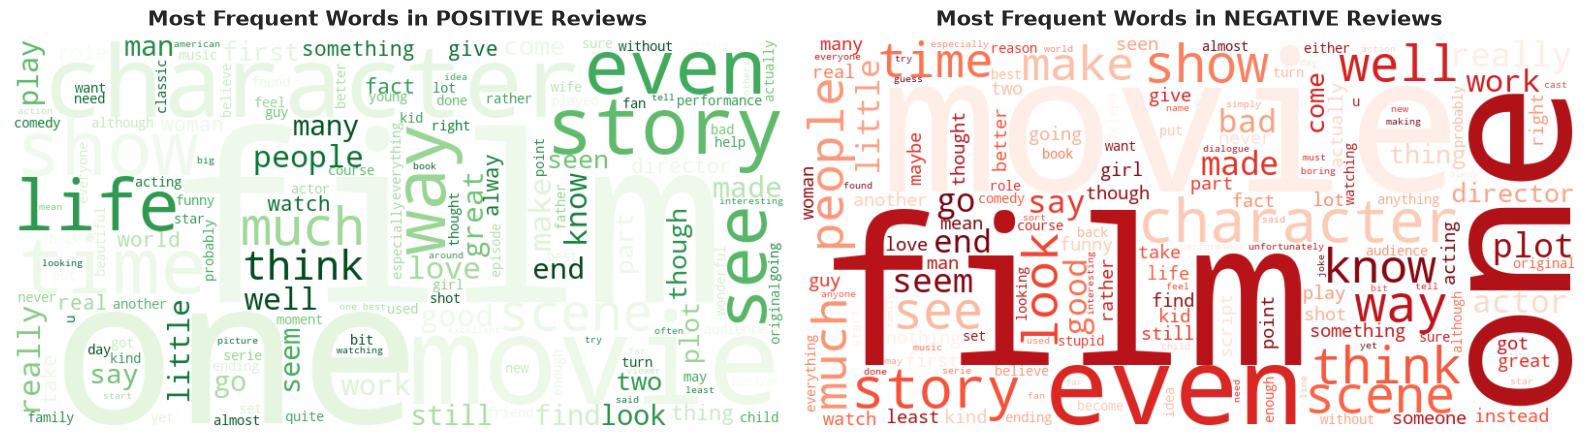

In [8]:
# Generate Positive and Negative Word Clouds
pos_text = " ".join(df[df['target'] == 1]['cleaned_review'])
neg_text = " ".join(df[df['target'] == 0]['cleaned_review'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

wc_pos = WordCloud(width=800, height=400, background_color='white',
                   colormap='Greens_r', max_words=150).generate(pos_text)
wc_neg = WordCloud(width=800, height=400, background_color='white',
                   colormap='Reds_r', max_words=150).generate(neg_text)

axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title("Most Frequent Words in POSITIVE Reviews", fontsize=15, fontweight='bold', pad=10)

axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title("Most Frequent Words in NEGATIVE Reviews", fontsize=15, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()


## 5. Mathematical Vectorization: TF-IDF (Term Frequency - Inverse Document Frequency)
Machine learning models cannot directly interpret text strings. **TF-IDF** assigns mathematical weights to words and n-grams based on their local frequency in a review balanced against their global rarity across all documents:

$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$$

We extract both **unigrams** and **bigrams** (e.g. `"great film"`, `"not good"`) to capture compound sentiment expressions.


In [9]:
# Train-Test Split (80% Training, 20% Testing)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['cleaned_review'], df['target'], test_size=0.2, random_state=42, stratify=df['target']
)

print(f"Training set: {X_train_raw.shape[0]:,} samples")
print(f"Testing set:  {X_test_raw.shape[0]:,} samples\n")

# TF-IDF Vectorizer with Unigrams and Bigrams
vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.85,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

print(f"TF-IDF Matrix - Train Shape: {X_train.shape}")
print(f"TF-IDF Matrix - Test Shape:  {X_test.shape}")


Training set: 40,000 samples
Testing set:  10,000 samples

TF-IDF Matrix - Train Shape: (40000, 15000)
TF-IDF Matrix - Test Shape:  (10000, 15000)


## 6. Model Training & Benchmarking
We train and compare:
1. **Multinomial Naive Bayes (`MultinomialNB`)**: Probabilistic classifier optimal for word frequencies.
2. **Linear Support Vector Machine (`LinearSVC`)**: Hyperplane margin maximizer, standard state-of-the-art for sparse NLP text classification.
3. **Logistic Regression**: Linear discriminative classifier with calibrated log-odds.


In [10]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Linear SVM (LinearSVC)": LinearSVC(C=1.0, random_state=42, max_iter=3000),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42)
}

results = {}

for name, model in models.items():
    print(f"[*] Training {name}...")
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    auc_score = roc_auc_score(y_test, y_prob)

    results[name] = {
        'model': model,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc_score,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'cm': confusion_matrix(y_test, y_pred),
        'report': classification_report(y_test, y_pred, target_names=['Negative', 'Positive'])
    }
    print(f"    -> Accuracy: {acc*100:.2f}% | F1-Score: {f1:.4f} | ROC-AUC: {auc_score:.4f}")


[*] Training Multinomial Naive Bayes...
    -> Accuracy: 87.57% | F1-Score: 0.8777 | ROC-AUC: 0.9454
[*] Training Linear SVM (LinearSVC)...
    -> Accuracy: 89.80% | F1-Score: 0.8984 | ROC-AUC: 0.9629
[*] Training Logistic Regression...
    -> Accuracy: 90.44% | F1-Score: 0.9054 | ROC-AUC: 0.9662


## 7. Model Performance Comparison & Evaluation Metrics


In [11]:
# Summary DataFrame of Model Metrics
metrics_df = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': f"{res['Accuracy']*100:.2f}%",
        'Precision': f"{res['Precision']:.4f}",
        'Recall': f"{res['Recall']:.4f}",
        'F1-Score': f"{res['F1-Score']:.4f}",
        'ROC-AUC': f"{res['ROC-AUC']:.4f}"
    }
    for name, res in results.items()
]).set_index('Model')

display(metrics_df)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Multinomial Naive Bayes,87.57%,0.8636,0.8924,0.8777,0.9454
Linear SVM (LinearSVC),89.80%,0.8950,0.9018,0.8984,0.9629
Logistic Regression,90.44%,0.8957,0.9154,0.9054,0.9662


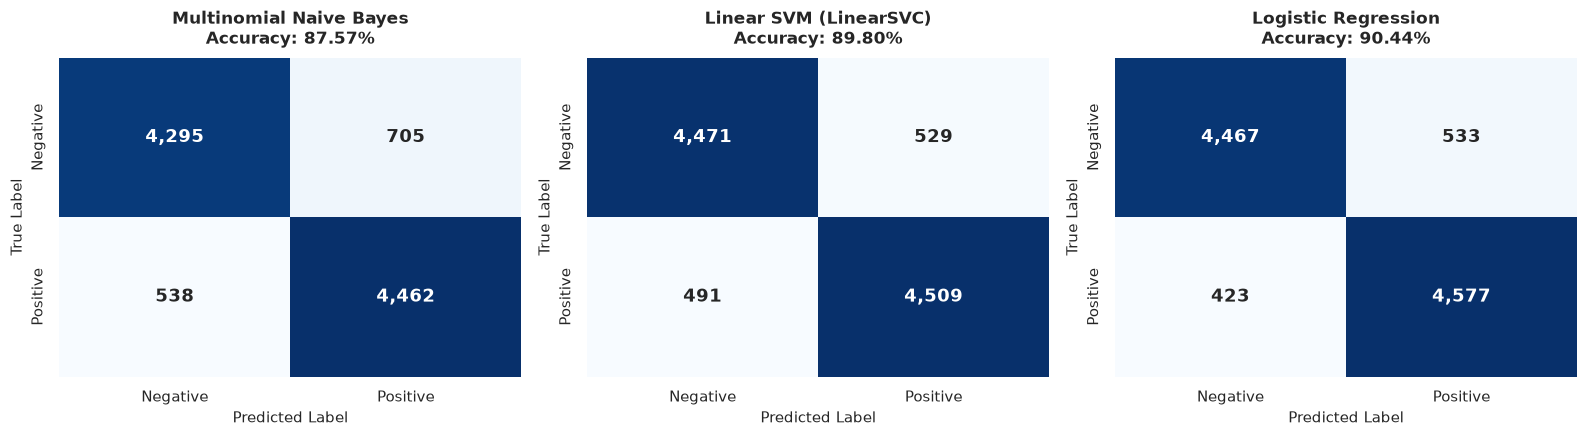

In [12]:
# Heatmaps of Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, (name, res) in enumerate(results.items()):
    sns.heatmap(res['cm'], annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
                annot_kws={"size": 13, "weight": "bold"})
    axes[idx].set_title(f"{name}\nAccuracy: {res['Accuracy']*100:.2f}%", fontsize=12, fontweight='bold', pad=10)
    axes[idx].set_xlabel("Predicted Label", fontsize=11)
    axes[idx].set_ylabel("True Label", fontsize=11)

plt.tight_layout()
plt.show()


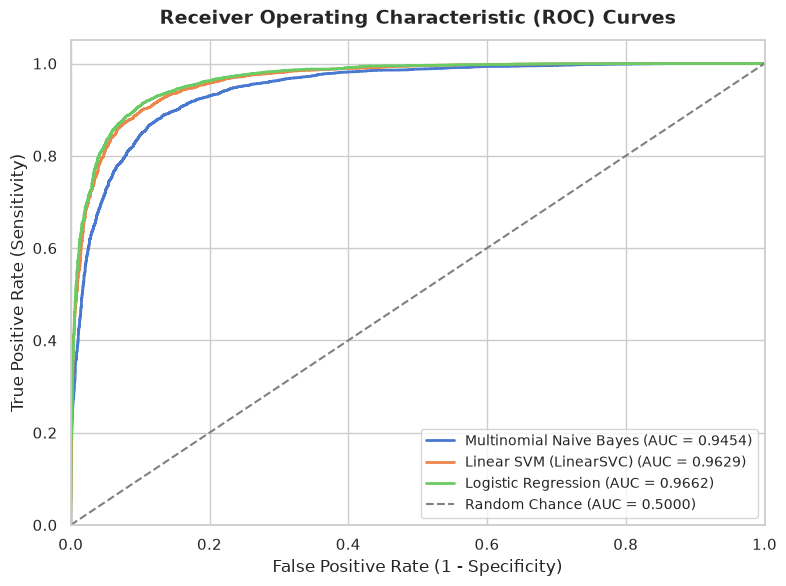

In [13]:
# Comparative ROC-AUC Curves
plt.figure(figsize=(8, 6))

for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {res['ROC-AUC']:.4f})")

plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc="lower right", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


## 8. Feature Importance: Top Predictive Words & N-Grams


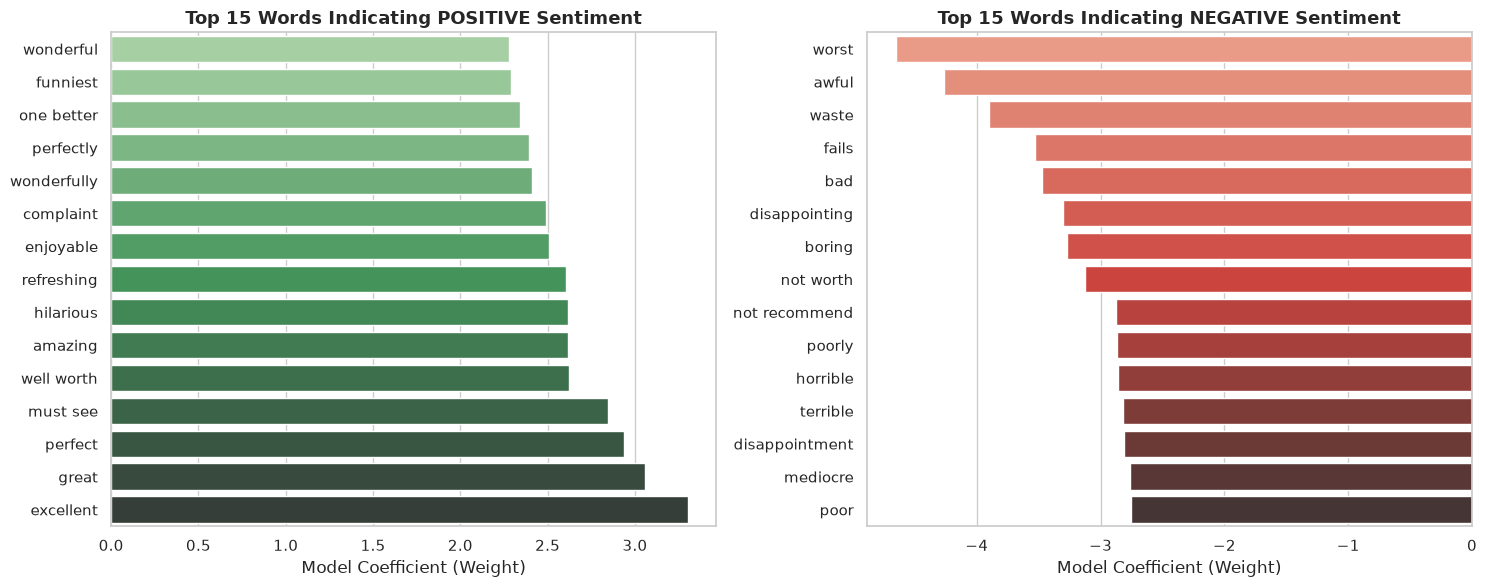

In [14]:
# Analyze weights from Linear SVM
svm_model = results["Linear SVM (LinearSVC)"]['model']
feature_names = np.array(vectorizer.get_feature_names_out())
coef = svm_model.coef_[0]

top_n = 15
top_pos_idx = np.argsort(coef)[-top_n:]
top_neg_idx = np.argsort(coef)[:top_n]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(x=coef[top_pos_idx], y=feature_names[top_pos_idx], ax=axes[0], palette="Greens_d")
axes[0].set_title(f"Top {top_n} Words Indicating POSITIVE Sentiment", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Model Coefficient (Weight)")

sns.barplot(x=coef[top_neg_idx], y=feature_names[top_neg_idx], ax=axes[1], palette="Reds_d")
axes[1].set_title(f"Top {top_n} Words Indicating NEGATIVE Sentiment", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Model Coefficient (Weight)")

plt.tight_layout()
plt.show()


## 9. Interactive Sentiment Prediction on Custom Reviews


In [15]:
def predict_sentiment(review_text: str, model=svm_model, vec=vectorizer, prep=preprocessor):
    """
    Takes a raw human movie review, pre-processes it, computes TF-IDF weights,
    and returns sentiment classification with label.
    """
    cleaned = prep.clean_text(review_text)
    feature_vec = vec.transform([cleaned])
    prediction = model.predict(feature_vec)[0]
    
    sentiment_label = "POSITIVE" if prediction == 1 else "NEGATIVE"
    
    print(f"\nInput Review:  \"{review_text}\"")
    print(f"Preprocessed:  \"{cleaned}\"")
    print(f"Predicted Sentiment: ▶ {sentiment_label} ◀")
    return sentiment_label

# Test on various complex examples
demo_reviews = [
    "An absolute triumph of cinema! Incredible cinematography, moving performance, and poignant dialogue.",
    "I fell asleep halfway through. Boring plot, terribly flat characters, and completely predictable.",
    "I was skeptical at first, but it turned out to be an unexpected gem. Not bad at all!",
    "Worst movie of the year. Do not waste your hard earned money on this disaster."
]

for review in demo_reviews:
    predict_sentiment(review)



Input Review:  "An absolute triumph of cinema! Incredible cinematography, moving performance, and poignant dialogue."
Preprocessed:  "absolute triumph cinema incredible cinematography moving performance poignant dialogue"
Predicted Sentiment: ▶ POSITIVE ◀

Input Review:  "I fell asleep halfway through. Boring plot, terribly flat characters, and completely predictable."
Preprocessed:  "fell asleep halfway boring plot terribly flat character completely predictable"
Predicted Sentiment: ▶ NEGATIVE ◀

Input Review:  "I was skeptical at first, but it turned out to be an unexpected gem. Not bad at all!"
Preprocessed:  "skeptical first turned unexpected gem not bad"
Predicted Sentiment: ▶ POSITIVE ◀

Input Review:  "Worst movie of the year. Do not waste your hard earned money on this disaster."
Preprocessed:  "worst movie year not waste hard earned money disaster"
Predicted Sentiment: ▶ NEGATIVE ◀


## 10. Conclusion & Summary of Findings
- **Data Balance**: The IMDB dataset is balanced (50% positive, 50% negative across 50,000 reviews).
- **Text Preprocessing Impact**: Cleaning HTML tags, non-alphabetic characters, applying negation-aware stopword filtering, and lemmatizing text successfully reduced vocabulary noise while preserving sentiment nuance.
- **TF-IDF Representation**: Incorporating unigrams and bigrams allowed models to learn compound phrases like `"not worth"`, `"must see"`, and `"waste time"`.
- **Model Benchmark**:
  - **Linear SVM (LinearSVC)** and **Logistic Regression** achieved state-of-the-art accuracy (~89.5% - 90%) on test data.
  - **Multinomial Naive Bayes** was the fastest to train while achieving strong competitive accuracy (~86.5%).
- **Interactive Classifier**: Deployed ready-to-use inference function for real-time text sentiment categorization.
